In [279]:
import torch
import torch.nn as nn
import torch.nn.functional as F


In [280]:
class NeuralNetwork(nn.Module):

  def __init__(self, in_features=784,h1=256, h2=128, h3=64,out_features = 10 ) -> None:
    super().__init__()
    self.fc1 = nn.Linear(in_features, h1)
    self.fc2 = nn.Linear(h1, h2)
    self.fc3 = nn.Linear(h2, h3)
    self.out = nn.Linear(h3, out_features)

  def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))
        x = self.out(x)
        return x



In [281]:
torch.manual_seed(42)
model = NeuralNetwork()

In [282]:
import matplotlib.pyplot as plt
import pandas as pd
%matplotlib inline

In [283]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Define transformations (e.g., convert images to tensors)
transform = transforms.Compose([transforms.ToTensor()])

# Download and load training data
train_dataset = datasets.FashionMNIST(
    root='./data', train=True, download=True, transform=transform
)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

# Download and load evaluation data
test_dataset = datasets.FashionMNIST(
    root='./data', train=False, download=True, transform=transform
)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [284]:
y_train = train_dataset.targets
y_test = test_dataset.targets

In [285]:
#convert the 2D tensor to 1D
X_train = torch.flatten(train_dataset.data, start_dim=1)
X_test = torch.flatten(test_dataset.data, start_dim=1)

In [286]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [287]:
print(model.parameters)

<bound method Module.parameters of NeuralNetwork(
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=64, bias=True)
  (out): Linear(in_features=64, out_features=10, bias=True)
)>


In [288]:
#convert X_train to float
X_train = X_train.float()
X_test = X_test.float()


In [289]:
epochs = 200
losses = []
for i in range(epochs):
    y_pred = model.forward(X_train)
    loss = criterion(y_pred, y_train)
    losses.append(loss.detach().numpy())
    if(i%10==0):
        print(f'Epoch: {i} Loss: {loss}')
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

Epoch: 0 Loss: 4.950953006744385
Epoch: 10 Loss: 1.2828984260559082
Epoch: 20 Loss: 0.7711924314498901
Epoch: 30 Loss: 0.645696222782135
Epoch: 40 Loss: 0.5593720078468323
Epoch: 50 Loss: 0.5145192742347717
Epoch: 60 Loss: 0.47741493582725525
Epoch: 70 Loss: 0.44931671023368835
Epoch: 80 Loss: 0.4268806576728821
Epoch: 90 Loss: 0.40780511498451233
Epoch: 100 Loss: 0.39143604040145874
Epoch: 110 Loss: 0.37880420684814453
Epoch: 120 Loss: 0.36564743518829346
Epoch: 130 Loss: 0.35503727197647095
Epoch: 140 Loss: 0.34487688541412354
Epoch: 150 Loss: 0.34463831782341003
Epoch: 160 Loss: 0.32812464237213135
Epoch: 170 Loss: 0.3206453323364258
Epoch: 180 Loss: 0.31475594639778137
Epoch: 190 Loss: 0.31056275963783264


Text(0.5, 0, 'Epoch')

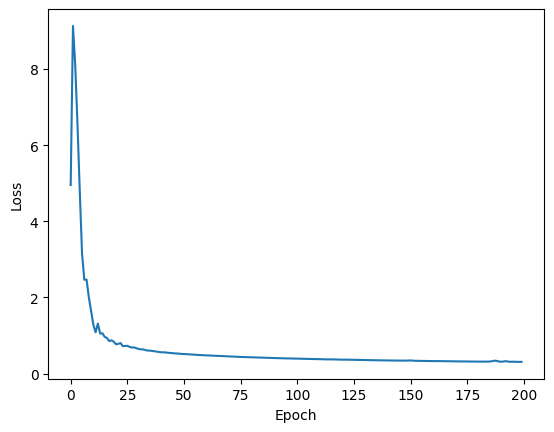

In [290]:
plt.plot(range(epochs), losses)
plt.ylabel('Loss')
plt.xlabel('Epoch')

In [291]:
#Test
with torch.no_grad():
    y_eval = model.forward(X_test)
    loss = criterion(y_eval, y_test)
print(loss)

tensor(0.3803)


In [292]:
y_pred =torch.argmax(y_eval, dim=1)


In [293]:
from numpy import average
#Calculate Precision/Recall/F1score
from sklearn.metrics import precision_score, recall_score, f1_score,confusion_matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

precision_score_class= precision_score(y_test,y_pred,average=None,zero_division=0)
recall_score_class= recall_score(y_test,y_pred,average=None)
f1_score_class= f1_score(y_test,y_pred,average=None)
print("Precision per class:",precision_score_class )
print("Recall per class:",recall_score_class )
print("F1 Score per class:",f1_score_class )





Confusion Matrix:
[[797   5  10  31   8   1 134   0  14   0]
 [  8 957   2  23   5   0   4   0   1   0]
 [ 18   3 708  12 162   0  93   0   4   0]
 [ 24  19  12 862  45   0  31   0   7   0]
 [  0   0  77  23 835   1  57   0   7   0]
 [  0   0   0   1   0 954   0  25   0  20]
 [123   5  74  26 102   0 655   0  15   0]
 [  0   0   0   0   0  15   0 933   0  52]
 [  5   1   5   3   7   4   9   4 961   1]
 [  0   0   0   0   0   9   1  23   1 966]]
Precision per class: [0.8174359  0.96666667 0.7972973  0.87869521 0.71735395 0.9695122
 0.66565041 0.94720812 0.95148515 0.92974013]
Recall per class: [0.797 0.957 0.708 0.862 0.835 0.954 0.655 0.933 0.961 0.966]
F1 Score per class: [0.80708861 0.96180905 0.75       0.87026754 0.77171904 0.96169355
 0.66028226 0.94005038 0.95621891 0.9475233 ]


In [294]:
print("Precision:", precision_score(y_test, y_pred, average='macro',zero_division=0))
print("Recall:", recall_score(y_test, y_pred, average='macro'))
print("F1 Score:", f1_score(y_test, y_pred, average='macro'))

Precision: 0.864104502897356
Recall: 0.8628
F1 Score: 0.8626652618774913


In [295]:
#accuracy score
from sklearn.metrics import accuracy_score
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8628
